In [1]:
!pip install ultralytics kagglehub

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.8/45.8 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 24.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.0/66.0 kB 2.7 MB/s eta 0:00:00


In [2]:
#download dataset

from pathlib import Path
import kagglehub

project_folder = Path("/content/ODOL")

raw_dataset_folder = project_folder / "dataset" / "raw"
source_dataset = raw_dataset_folder / "Truck counting.v1i.yolov8"
clean_dataset = project_folder / "dataset" / "cleaned"
results_folder = project_folder / "results"

raw_dataset_folder.mkdir(parents=True, exist_ok=True)

kagglehub.dataset_download(
    "beethoo/trucks-detection",
    output_dir="/content/ODOL/dataset/raw"
)

source_dataset

100%|██████████| 226M/226M [00:02<00:00, 85.4MB/s]

Extracting files...


PosixPath('/content/ODOL/dataset/raw/Truck counting.v1i.yolov8')

In [3]:
#collect images and labels

image_label_pairs = []

for split_name in ["train", "test", "valid"]:
    image_folder = source_dataset / split_name / "images"
    label_folder = source_dataset / split_name / "labels"

    for image_file in sorted(image_folder.glob("*.jpg")):
        label_file = label_folder / f"{image_file.stem}.txt"
        image_label_pairs.append((image_file, label_file))

len(image_label_pairs)

1769

In [4]:
#group augmented copies

image_groups = {}

for image_file, label_file in image_label_pairs:
    original_name = image_file.stem.split(".rf.")[0]

    if original_name not in image_groups:
        image_groups[original_name] = []

    image_groups[original_name].append(
        (image_file, label_file)
    )

len(image_groups)

193

In [5]:
#split group

import random

random.seed(42)

group_names = sorted(image_groups.keys())
random.shuffle(group_names)

train_count = round(len(group_names) * 0.70)
valid_count = round(len(group_names) * 0.15)

train_groups = group_names[:train_count]
valid_groups = group_names[train_count:train_count + valid_count]
test_groups = group_names[train_count + valid_count:]

print("Train groups:", len(train_groups))
print("Validation groups:", len(valid_groups))
print("Test groups:", len(test_groups))

Train groups: 135
Validation groups: 29
Test groups: 29


In [6]:
#copy into clean dataset

import shutil

shutil.rmtree(clean_dataset, ignore_errors=True)

split_groups = {
    "train": train_groups,
    "valid": valid_groups,
    "test": test_groups
}

for split_name, groups in split_groups.items():
    image_folder = clean_dataset / split_name / "images"
    label_folder = clean_dataset / split_name / "labels"

    image_folder.mkdir(parents=True)
    label_folder.mkdir(parents=True)

    for group_name in groups:
        for image_file, label_file in image_groups[group_name]:
            shutil.copy2(
                image_file,
                image_folder / image_file.name
            )

            shutil.copy2(
                label_file,
                label_folder / label_file.name
            )

In [7]:
#create data_yml

data_yaml = clean_dataset / "data.yaml"

data_yaml.write_text(
    """train: ./train/images
val: ./valid/images
test: ./test/images

nc: 1
names: ["truck"]
"""
)

data_yaml

PosixPath('/content/ODOL/dataset/cleaned/data.yaml')

In [8]:
#train the model

from ultralytics import YOLO

model = YOLO("yolov8m.pt")

training_name = "training_patience15"

model.train(
    data=data_yaml,
    epochs=100,
    imgsz=640,
    batch=4,
    seed=42,
    patience=15,
    plots=True,
    project=results_folder,
    name=training_name,
    exist_ok=True
)

Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.
Ultralytics 8.4.130 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/ODOL/dataset/cleaned/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipu

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7c86ac2924a0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [9]:
# load the best trained model

best_model_path = (
    results_folder
    / training_name
    / "weights"
    / "best.pt"
)

best_model = YOLO(best_model_path)

test_name = "test_training_patience15"

best_model_path

PosixPath('/content/ODOL/results/training_patience15/weights/best.pt')

In [10]:
# evaluate the best model using test data

test_results = best_model.val(
    data=data_yaml,
    split="test",
    plots=True,
    project=results_folder,
    name=test_name,
    exist_ok=True
)

Ultralytics 8.4.130 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 93 layers, 25,840,339 parameters, 0 gradients, 78.7 GFLOPs
test: Fast image access ✅ (ping: 0.0±0.0 ms, read: 50.1±33.6 MB/s, size: 130.6 KB)
test: Scanning /content/ODOL/dataset/cleaned/test/labels... 272 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 272/272 561.9it/s 0.5s
test: New cache created: /content/ODOL/dataset/cleaned/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 17/17 2.0it/s 8.6s
                   all        272        924      0.948       0.87      0.936      0.814
Speed: 3.3ms preprocess, 21.9ms inference, 0.0ms loss, 1.6ms postprocess per image
Results saved to /content/ODOL/results/test_training_patience15


In [11]:
# show test results
print("Precision:", round(test_results.box.mp, 4))
print("Recall:", round(test_results.box.mr, 4))
print("F1 score:", round(test_results.box.f1.mean(), 4))
print("mAP50:", round(test_results.box.map50, 4))
print("mAP50-95:", round(test_results.box.map, 4))

Precision: 0.9481
Recall: 0.87
F1 score: 0.9074
mAP50: 0.9363
mAP50-95: 0.8144


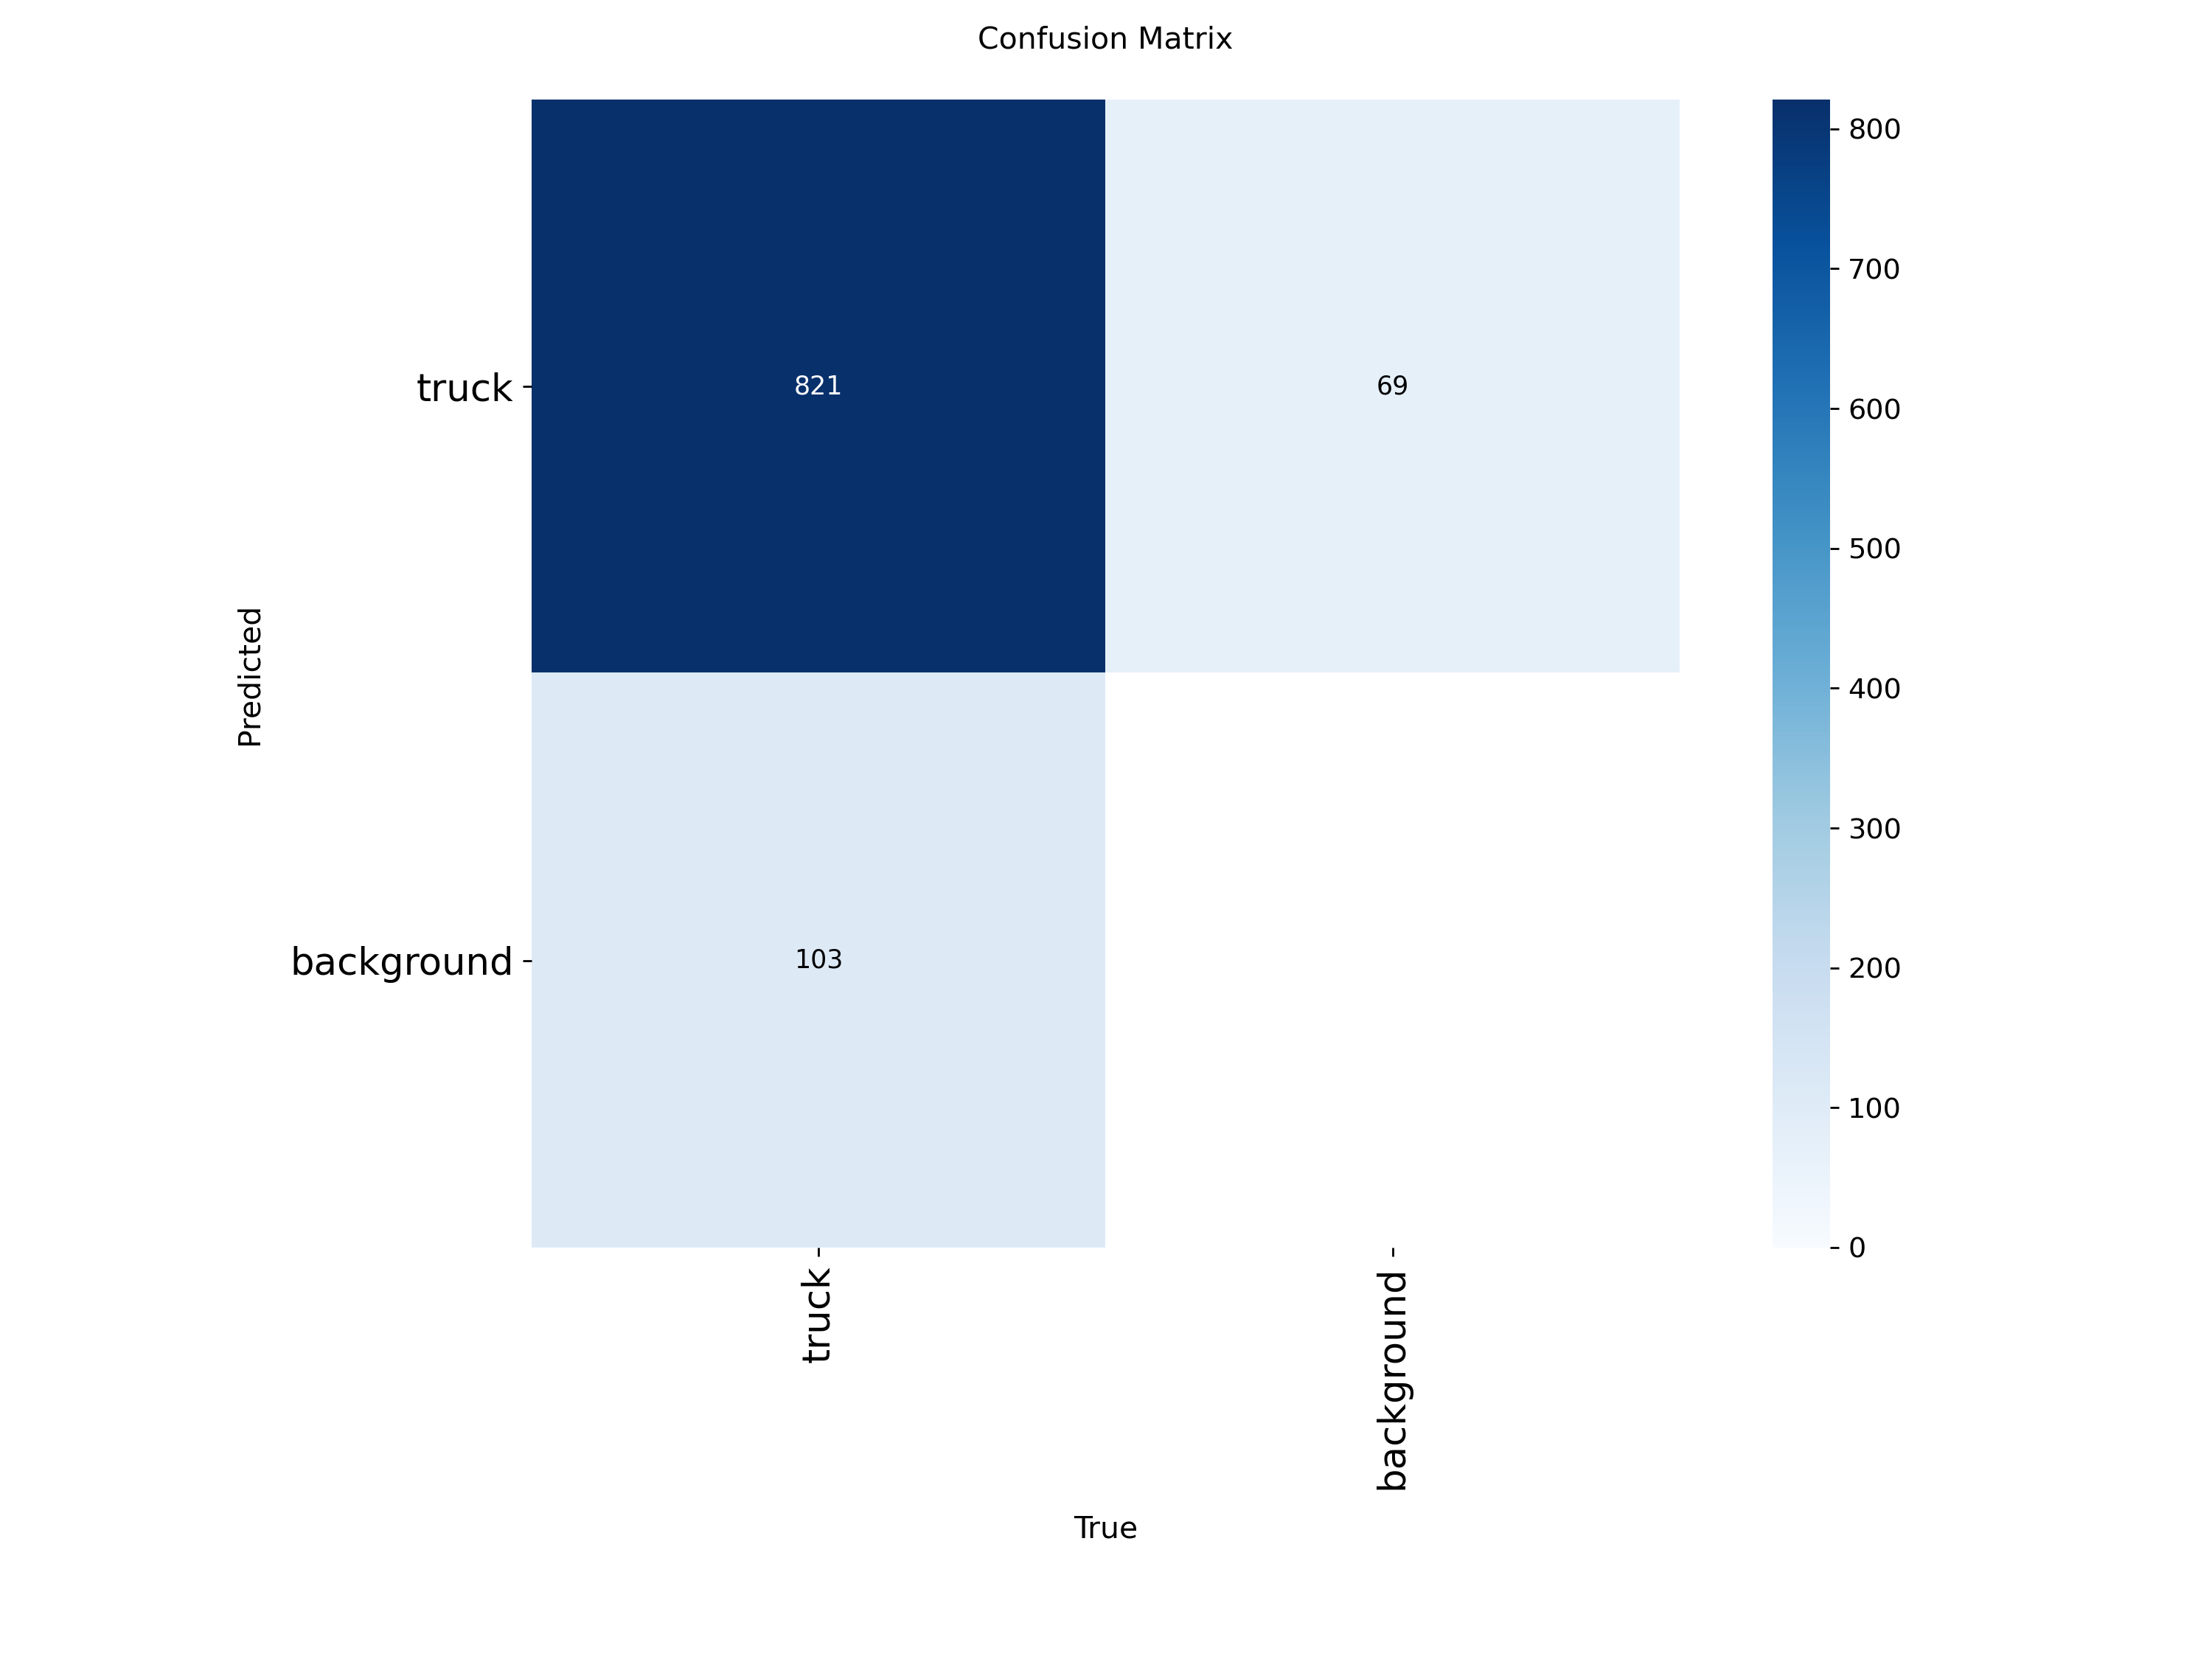

In [12]:
# show the test confusion matrix

from IPython.display import Image

Image(
    "/content/ODOL/results/test_training_patience15/confusion_matrix.png",
    width=700
)

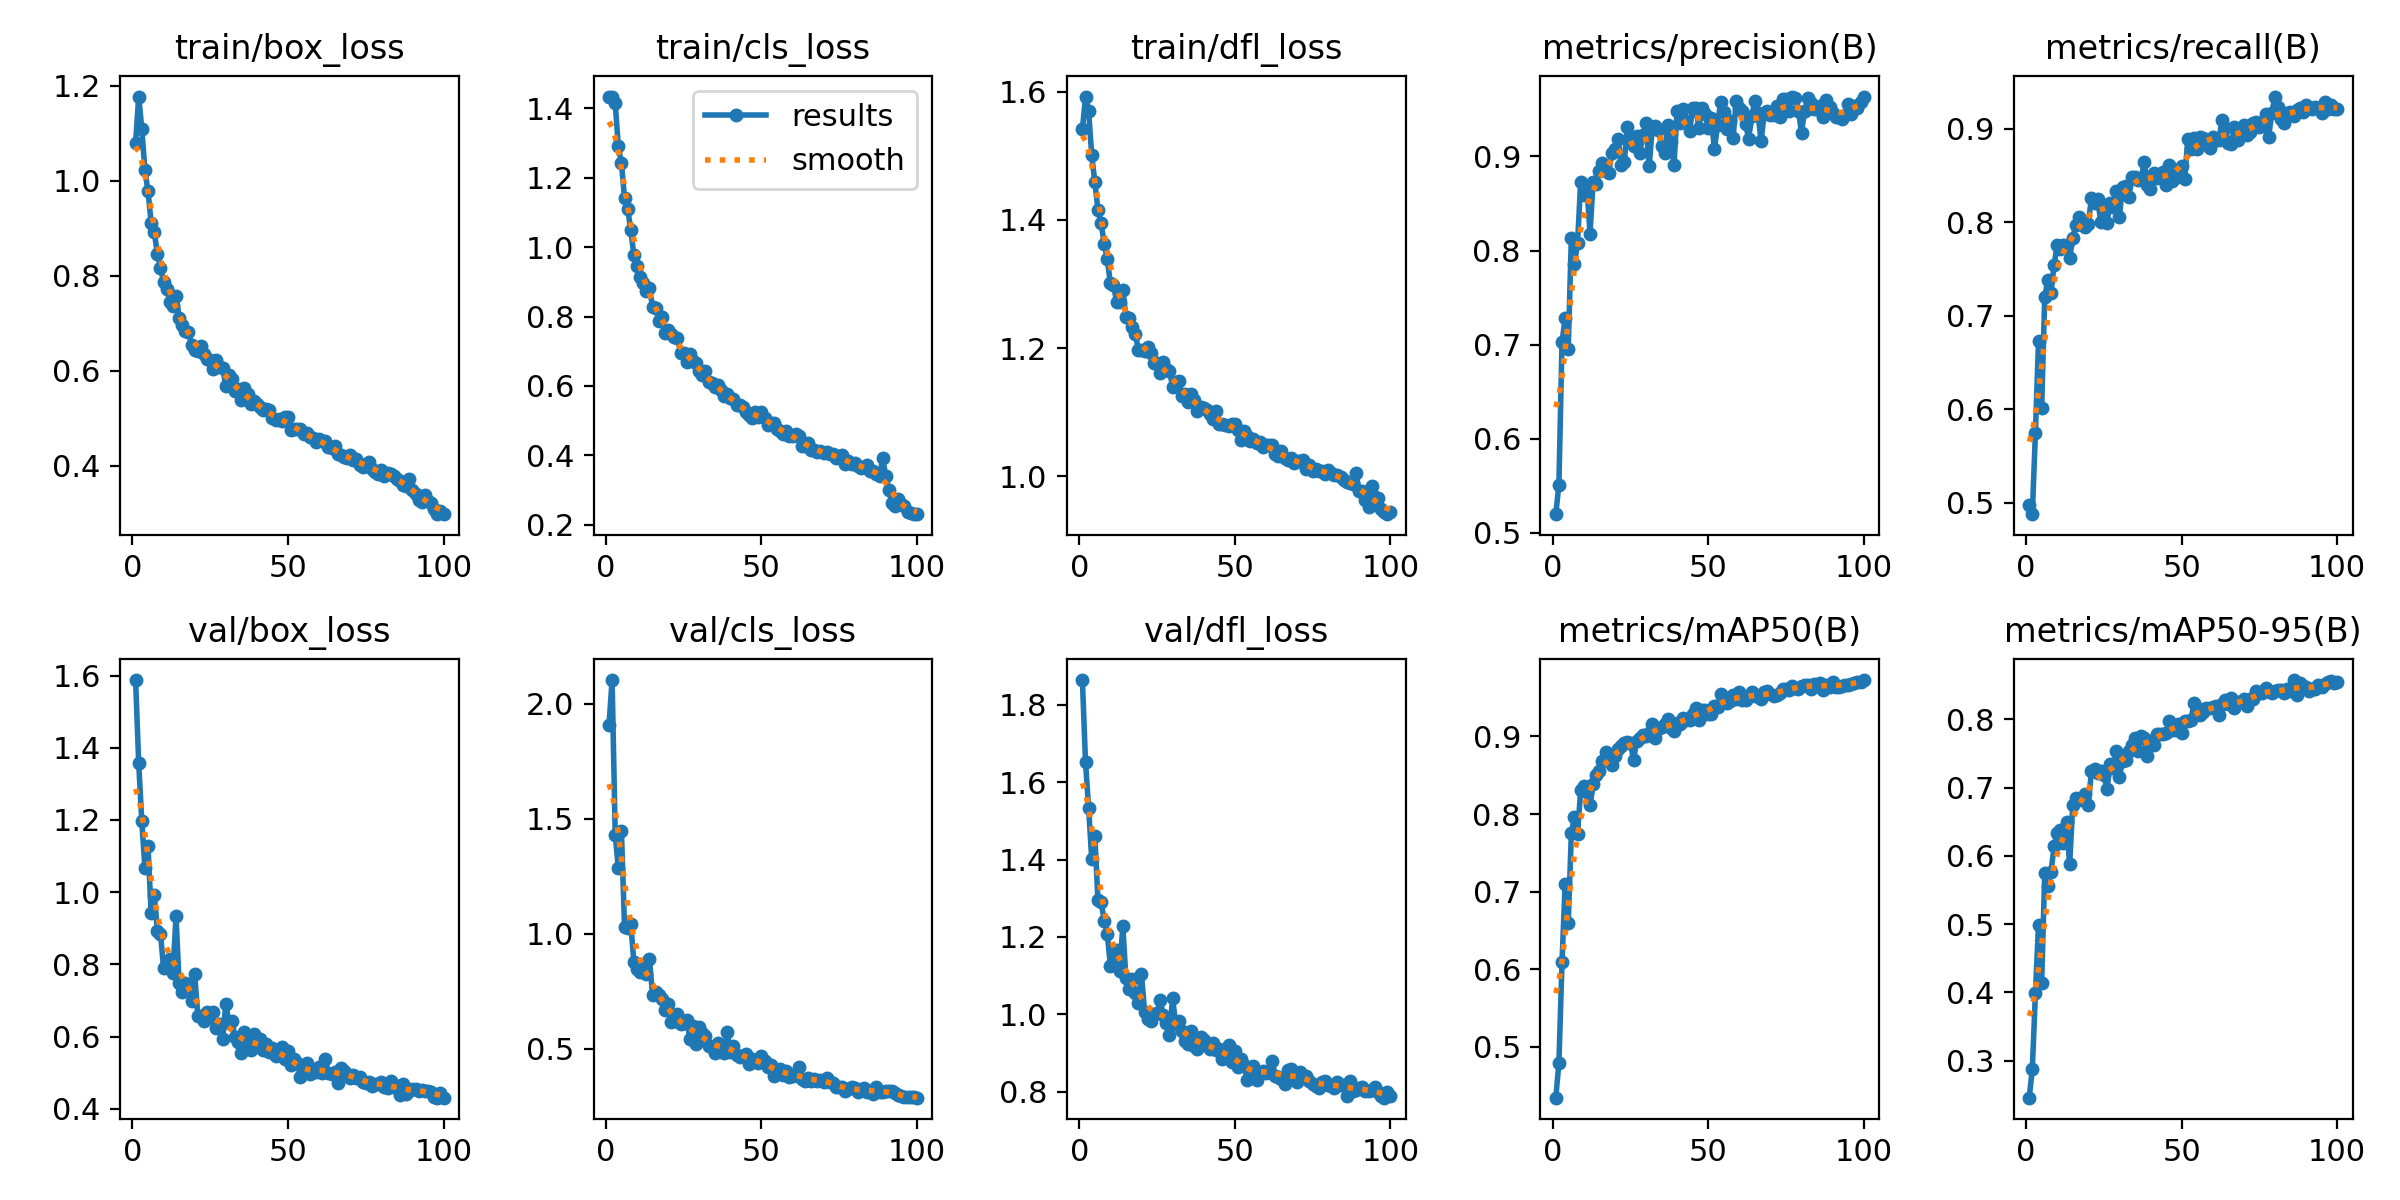

In [17]:
# show training progress

Image("/content/ODOL/results/training_patience15/results.png", width=900)

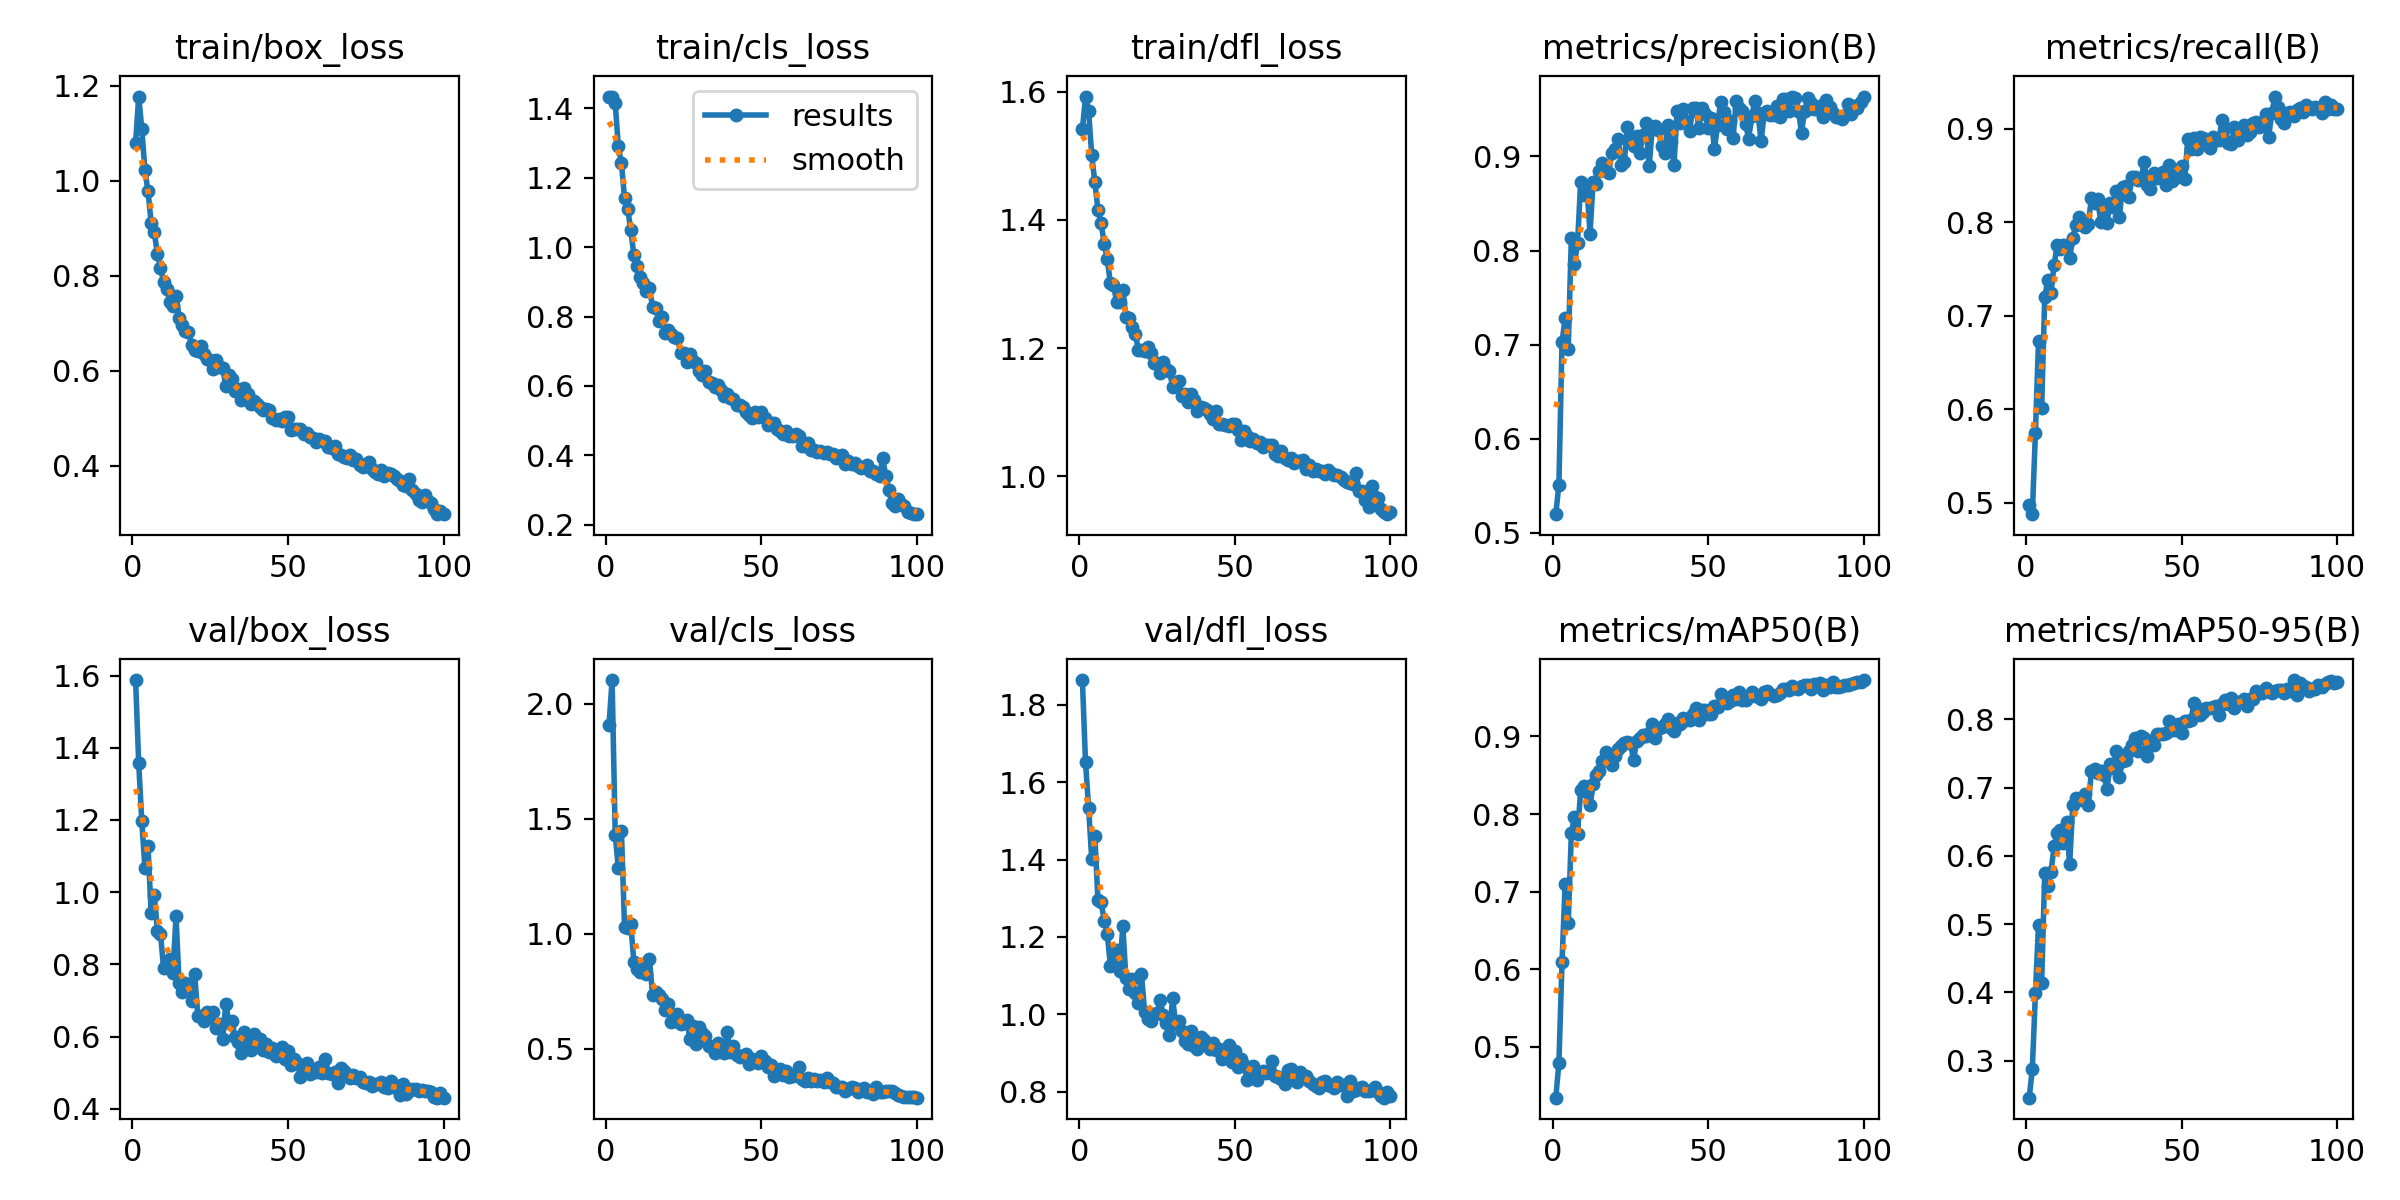

In [15]:
# show truck detection examples

Image("/content/ODOL/results/training_patience15/results.png", width=900)

In [16]:
from google.colab import files

files.download(
    "/content/ODOL/results/training_patience15/weights/best.pt"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>